In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import sys
sys.path.append("..")    
from src.data.data import build_auctions

In [20]:
PRODUCT = "mFRR"
FREQUENCY = "weekly"
auctions = build_auctions(product=PRODUCT)          # team table: src/data/data.py
auctions = auctions[auctions["freq"] == FREQUENCY]
# TRL_19_KW42_KORR_up is a second (correction) auction for the same week, direction
# and gate closure as TRL_19_KW42_up. Kept in the team table (counts match the
# statement); dropped here so that each week has one auction per direction.
# Open team question, see questions.txt.
auctions = auctions[~auctions["auction_id"].str.contains("KORR")].reset_index(drop=True)
auctions.groupby("direction")["auction_id"].nunique()

direction
downwards    410
upwards      410
Name: auction_id, dtype: int64

In [21]:
auctions.groupby("direction")["marginal"].describe()

,count,mean,std,min,25%,50%,75%,max
direction,,,,,,,,
downwards,410.0,2096.551390,2784.066896,55.00,419.00,1103.55,2191.050,17802.7
upwards,410.0,516.921756,580.151743,28.56,156.43,367.96,592.675,4000.0


In [22]:
COLORS = {"upwards": "tab:blue", "downwards": "tab:orange"}
DIRECTIONS = ["upwards", "downwards"]


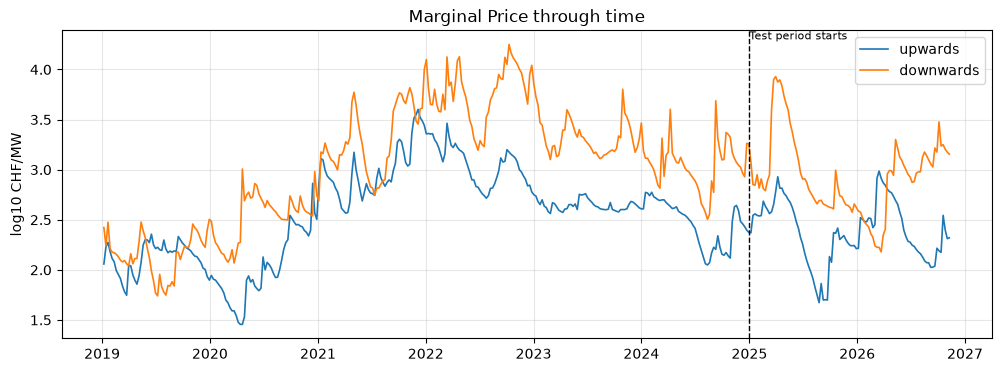

In [23]:
fig, ax = plt.subplots(figsize=(12, 4))

for direction in DIRECTIONS:
    d = auctions[auctions["direction"] == direction]
    ax.plot(d["date"], d["y"], label=direction, linewidth=1.2, color=COLORS[direction])

ax.axvline(pd.Timestamp("2025-01-01"), color="black", linestyle="--", linewidth=1)
ax.text(pd.Timestamp("2025-01-01"), ax.get_ylim()[1], "Test period starts ", va="top", fontsize=8)

ax.set_title("Marginal Price through time")
ax.set_ylabel("log10 CHF/MW")
ax.legend()
ax.grid(alpha=0.3)

fig.savefig("../figures/fig1_price_time.png", dpi=150, bbox_inches="tight")


In [24]:

auctions[["n_bids", "n_accepted", "offered", "awarded", "supply_ratio"]].describe()

,n_bids,n_accepted,offered,awarded,supply_ratio
count,820.000000,820.000000,820.000000,820.000000,820.000000
mean,33.664634,18.804878,774.360976,355.795122,2.448391
std,10.581896,6.749918,194.778592,121.065354,1.106559
min,14.000000,3.000000,308.000000,39.000000,1.000000
25%,26.000000,14.000000,621.500000,263.000000,1.766740
50%,33.000000,19.000000,775.000000,361.500000,2.139601
75%,40.000000,23.000000,908.000000,462.250000,2.709426
max,71.000000,41.000000,1436.000000,555.000000,10.000000


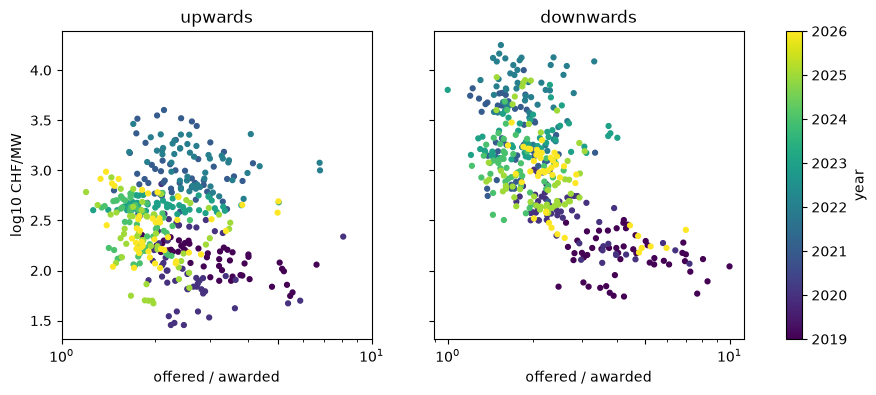

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

for ax, direction in zip(axes, DIRECTIONS):
    d = auctions[auctions["direction"] == direction]
    sc = ax.scatter(d["supply_ratio"], d["y"], c=d["date"].dt.year, cmap="viridis", s=12)
    ax.set_xscale("log")
    ax.set_xticks([1, 5, 10])
    ax.set_title(direction)
    ax.set_xlabel("offered / awarded")

axes[0].set_ylabel("log10 CHF/MW")
fig.colorbar(sc, ax=axes, label="year")
fig.savefig("../figures/prices_vs_supply_ratio.png", dpi=150, bbox_inches="tight")


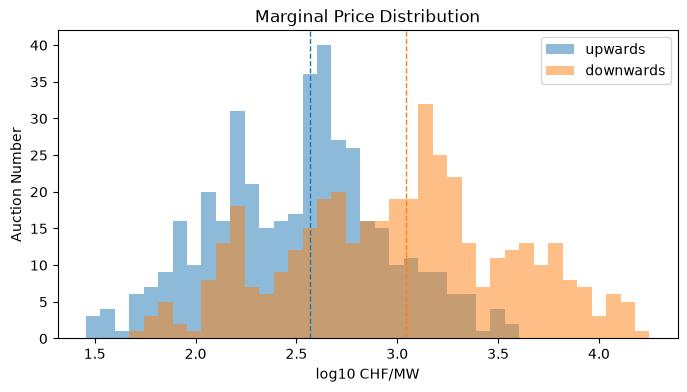

In [26]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(auctions["y"].min(), auctions["y"].max(), 40) 

for direction in DIRECTIONS:
    d = auctions[auctions["direction"] == direction]["y"].dropna()
    ax.hist(d, bins=bins, alpha=0.5, color=COLORS[direction], label=direction)
    ax.axvline(d.median(), color=COLORS[direction], linestyle="--", linewidth=1)   

ax.set_xlabel("log10 CHF/MW")
ax.set_ylabel("Auction Number")
ax.set_title("Marginal Price Distribution")
ax.legend()
fig.savefig("../figures/fig3_distribution.png", dpi=150, bbox_inches="tight")

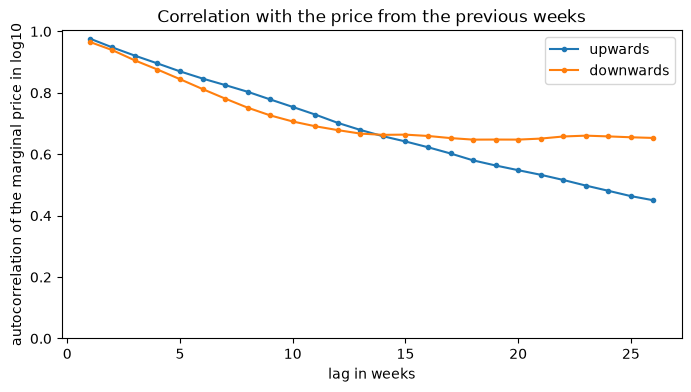

In [27]:
lags = range(1, 27)
fig, ax = plt.subplots(figsize=(8, 4))

for direction in DIRECTIONS:
    s = auctions[auctions["direction"] == direction].sort_values("date")["y"]
    acf = [s.autocorr(lag=k) for k in lags]
    ax.plot(lags, acf, marker="o", markersize=3, color=COLORS[direction], label=direction)

ax.set_xlabel("lag in weeks")
ax.set_ylim(bottom=0)
ax.set_ylabel("autocorrelation of the marginal price in log10")
ax.set_title("Correlation with the price from the previous weeks")
ax.legend()
fig.savefig("../figures/fig4_autocorrelation.png", dpi=150, bbox_inches="tight")

direction,downwards,upwards
date,,
2019,149.0,149.0
2020,380.0,88.0
2021,1794.0,819.0
2022,6386.0,1204.0
2023,1911.0,430.0
2024,1176.0,318.0
2025,694.0,233.0
2026,954.0,250.0


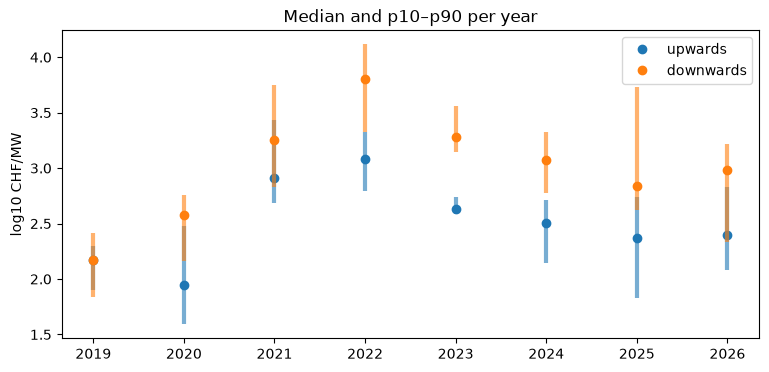

In [28]:
fig, ax = plt.subplots(figsize=(9, 4))

for i, direction in enumerate(DIRECTIONS):
    d = auctions[auctions["direction"] == direction]
    q = d.groupby(d["date"].dt.year)["y"].quantile([0.1, 0.5, 0.9]).unstack()        
    ax.vlines(q.index, q[0.1], q[0.9], color=COLORS[direction], linewidth=3, alpha=0.6)
    ax.plot(q.index, q[0.5], "o", color=COLORS[direction], label=direction)

ax.set_xticks(sorted(auctions["date"].dt.year.unique()))
ax.set_ylabel("log10 CHF/MW")
ax.set_title("Median and p10–p90 per year")
ax.legend()
fig.savefig("../figures/fig5_regimes.png", dpi=150, bbox_inches="tight")

auctions.pivot_table(index=auctions["date"].dt.year, columns="direction", values="marginal", aggfunc="median").round(0)

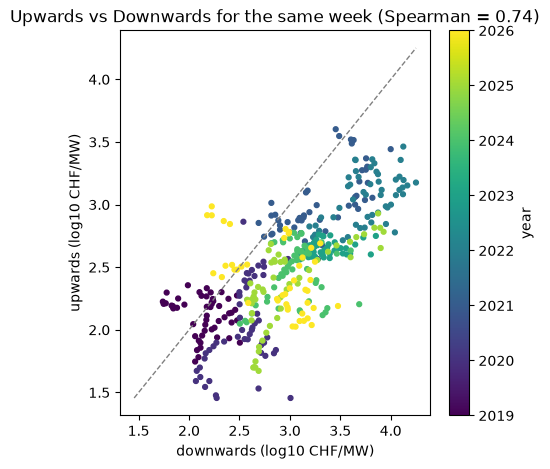

In [29]:
wide = auctions.pivot(index="date", columns="direction", values="y")   

fig, ax = plt.subplots(figsize=(5, 5))
sc = ax.scatter(wide["downwards"], wide["upwards"], c=wide.index.year, cmap="viridis", s=12)
lo, hi = np.nanmin(wide.values), np.nanmax(wide.values)
ax.plot([lo, hi], [lo, hi], color="gray", linestyle="--", linewidth=1)  
ax.set_xlabel("downwards (log10 CHF/MW)")
ax.set_ylabel("upwards (log10 CHF/MW)")
ax.set_title(f"Upwards vs Downwards for the same week (Spearman = {wide.corr(method='spearman').iloc[0, 1]:.2f})")
fig.colorbar(sc, label="year")
fig.savefig("../figures/fig6_up_vs_down.png", dpi=150, bbox_inches="tight")

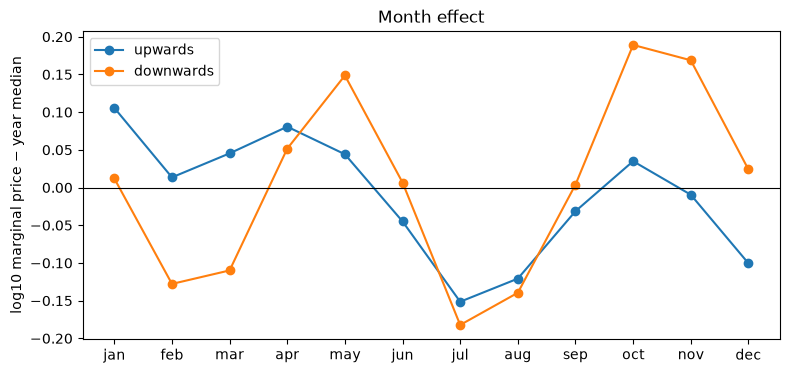

In [30]:
year_median = auctions.groupby(["direction", auctions["date"].dt.year])["y"].transform("median")
auctions["log10_vs_year"] = auctions["y"] - year_median

fig, ax = plt.subplots(figsize=(9, 4))
for direction in DIRECTIONS:
    d = auctions[auctions["direction"] == direction]
    m = d.groupby(d["date"].dt.month)["log10_vs_year"].median()
    ax.plot(m.index, m.values, marker="o", color=COLORS[direction], label=direction)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(range(1, 13), ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"])
ax.set_ylabel("log10 marginal price − year median")
ax.set_title("Month effect")
ax.legend()
fig.savefig("../figures/fig8_seasonality.png", dpi=150, bbox_inches="tight")

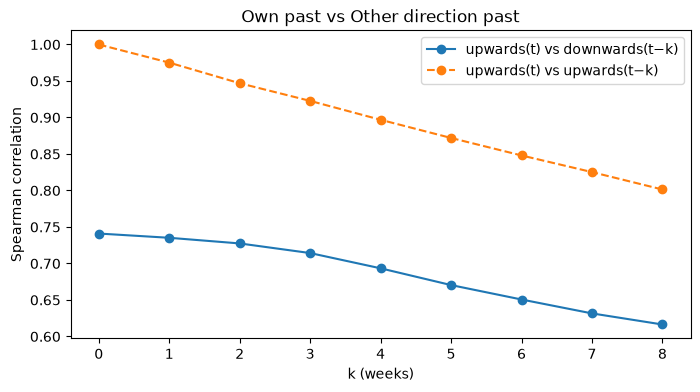

In [32]:
wide = auctions.pivot(index="date", columns="direction", values="log10_price")
lags = range(0, 9)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(lags, [wide["upwards"].corr(wide["downwards"].shift(k), method="spearman") for k in lags],
        marker="o", label="upwards(t) vs downwards(t−k)")
ax.plot(lags, [wide["upwards"].corr(wide["upwards"].shift(k), method="spearman") for k in lags],
        marker="o", linestyle="--", label="upwards(t) vs upwards(t−k)")
ax.set_xlabel("k (weeks)")
ax.set_ylabel("Spearman correlation")
ax.set_title("Own past vs Other direction past")
ax.legend()